<a href="https://colab.research.google.com/github/HanJay09/EDA_LSTM-RNN_SP500_Stocks/blob/main/EDA_LSTM(RNN)_S%26P500_Stocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploratory Data Analysis (EDA)**


**Data Loading**

In [ ]:
!pip install pandas numpy matplotlib plotly seaborn kaggle ipython scikit-learn tensorflow keras-tuner

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import kagglehub
from IPython.display import display
from plotly.graph_objects import Candlestick
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras import metrics
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from keras_tuner import RandomSearch
from keras_tuner.engine.hyperparameters import HyperParameters

In [ ]:
# Download latest version of the dataset(s)
path = kagglehub.dataset_download("andrewmvd/sp-500-stocks")

# Check if the dataset(s) file path exists
print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/andrewmvd/sp-500-stocks/versions/1023


In [ ]:
# Load & Read the dataset(s)
stocks_csv_path = f"{path}/sp500_stocks.csv"
stocks_df = pd.read_csv(stocks_csv_path)

index_csv_path = f"{path}/sp500_index.csv"
index_df = pd.read_csv(index_csv_path)

companies_csv_path = f"{path}/sp500_companies.csv"
companies_df = pd.read_csv(companies_csv_path)

**Data Exploration**

In [ ]:
# --- Inspect the dataset(s) ---

# Display the first few rows of the DataFrame
display(stocks_df.head())
display(index_df.head())
display(companies_df.head())

,Date,Symbol,Adj Close,Close,High,Low,Open,Volume
0,2010-01-04,MMM,NaN,NaN,NaN,NaN,NaN,NaN
1,2010-01-05,MMM,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-06,MMM,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-07,MMM,NaN,NaN,NaN,NaN,NaN,NaN
4,2010-01-08,MMM,NaN,NaN,NaN,NaN,NaN,NaN


,Date,S&P500
0,2014-12-22,2078.54
1,2014-12-23,2082.17
2,2014-12-24,2081.88
3,2014-12-26,2088.77
4,2014-12-29,2090.57


,Exchange,Symbol,Shortname,Longname,Sector,Industry,Currentprice,Marketcap,Ebitda,Revenuegrowth,City,State,Country,Fulltimeemployees,Longbusinesssummary,Weight
0,NMS,AAPL,Apple Inc.,Apple Inc.,Technology,Consumer Electronics,254.49,3846819807232,1.346610e+11,0.061,Cupertino,CA,United States,164000.0,"Apple Inc. designs, manufactures, and markets ...",0.069209
1,NMS,NVDA,NVIDIA Corporation,NVIDIA Corporation,Technology,Semiconductors,134.70,3298803056640,6.118400e+10,1.224,Santa Clara,CA,United States,29600.0,NVIDIA Corporation provides graphics and compu...,0.059350
2,NMS,MSFT,Microsoft Corporation,Microsoft Corporation,Technology,Software - Infrastructure,436.60,3246068596736,1.365520e+11,0.160,Redmond,WA,United States,228000.0,Microsoft Corporation develops and supports so...,0.058401
3,NMS,AMZN,"Amazon.com, Inc.","Amazon.com, Inc.",Consumer Cyclical,Internet Retail,224.92,2365033807872,1.115830e+11,0.110,Seattle,WA,United States,1551000.0,"Amazon.com, Inc. engages in the retail sale of...",0.042550
4,NMS,GOOGL,Alphabet Inc.,Alphabet Inc.,Communication Services,Internet Content & Information,191.41,2351625142272,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309


In [ ]:
# Display information about the DataFrame, including data types and missing values
stocks_df.info(), index_df.info(), companies_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1891536 entries, 0 to 1891535
Data columns (total 8 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date       object 
 1   Symbol     object 
 2   Adj Close  float64
 3   Close      float64
 4   High       float64
 5   Low        float64
 6   Open       float64
 7   Volume     float64
dtypes: float64(6), object(2)
memory usage: 115.5+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    2517 non-null   object 
 1   S&P500  2517 non-null   float64
dtypes: float64(1), object(1)
memory usage: 39.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Exchange             502 non-null    object 
 1   Symbol               502 no

(None, None, None)

In [ ]:
# Check dataset(s) shape
stocks_df.shape, index_df.shape, companies_df.shape

((1891536, 8), (2517, 2), (502, 16))

In [ ]:
# Display the column names of the DataFrame
stocks_df.columns, index_df.columns, companies_df.columns

(Index(['Date', 'Symbol', 'Adj Close', 'Close', 'High', 'Low', 'Open',
        'Volume'],
       dtype='object'),
 Index(['Date', 'S&P500'], dtype='object'),
 Index(['Exchange', 'Symbol', 'Shortname', 'Longname', 'Sector', 'Industry',
        'Currentprice', 'Marketcap', 'Ebitda', 'Revenuegrowth', 'City', 'State',
        'Country', 'Fulltimeemployees', 'Longbusinesssummary', 'Weight'],
       dtype='object'))

In [ ]:
# Display the column names as lists
stocks_df.columns.tolist()
index_df.columns.tolist()
companies_df.columns.tolist()

['Exchange',
 'Symbol',
 'Shortname',
 'Longname',
 'Sector',
 'Industry',
 'Currentprice',
 'Marketcap',
 'Ebitda',
 'Revenuegrowth',
 'City',
 'State',
 'Country',
 'Fulltimeemployees',
 'Longbusinesssummary',
 'Weight']

In [ ]:
# Generate descriptive statistics of the DataFrames
stocks_df.describe(), index_df.describe(), companies_df.describe()

(           Adj Close          Close           High            Low  \
 count  617831.000000  617831.000000  617831.000000  617831.000000   
 mean       79.672357      87.471540      88.417844      86.480997   
 std       102.742931     104.521901     105.684113     103.300770   
 min         0.203593       0.222000       0.226250       0.216250   
 25%        26.572459      32.700001      33.060001      32.299999   
 50%        49.821613      59.139999      59.720001      58.500000   
 75%        94.831036     105.019997     106.129997     103.889999   
 max      1702.530029    1702.530029    1714.750000    1696.900024   
 
                 Open        Volume  
 count  617831.000000  6.178310e+05  
 mean       87.460302  9.347125e+06  
 std       104.519845  4.771669e+07  
 min         0.218000  0.000000e+00  
 25%        32.689999  1.144000e+06  
 50%        59.119999  2.453400e+06  
 75%       105.000000  5.657850e+06  
 max      1706.400024  3.692928e+09  ,
             S&P500
 coun

In [ ]:
# Check for missing values in the DataFrames, return boolean values
stocks_df.isnull(), index_df.isnull(), companies_df.isnull()

(          Date  Symbol  Adj Close  Close  High   Low  Open  Volume
 0        False   False       True   True  True  True  True    True
 1        False   False       True   True  True  True  True    True
 2        False   False       True   True  True  True  True    True
 3        False   False       True   True  True  True  True    True
 4        False   False       True   True  True  True  True    True
 ...        ...     ...        ...    ...   ...   ...   ...     ...
 1891531  False   False       True   True  True  True  True    True
 1891532  False   False       True   True  True  True  True    True
 1891533  False   False       True   True  True  True  True    True
 1891534  False   False       True   True  True  True  True    True
 1891535  False   False       True   True  True  True  True    True
 
 [1891536 rows x 8 columns],
        Date  S&P500
 0     False   False
 1     False   False
 2     False   False
 3     False   False
 4     False   False
 ...     ...     ...
 2512 

In [ ]:
# Calculate the total number of missing values in each column
stocks_df.isnull().sum(), index_df.isnull().sum(), companies_df.isnull().sum()

(Date               0
 Symbol             0
 Adj Close    1273705
 Close        1273705
 High         1273705
 Low          1273705
 Open         1273705
 Volume       1273705
 dtype: int64,
 Date      0
 S&P500    0
 dtype: int64,
 Exchange                0
 Symbol                  0
 Shortname               0
 Longname                0
 Sector                  0
 Industry                0
 Currentprice            0
 Marketcap               0
 Ebitda                 29
 Revenuegrowth           3
 City                    0
 State                  20
 Country                 0
 Fulltimeemployees       9
 Longbusinesssummary     0
 Weight                  0
 dtype: int64)

In [ ]:
# Check for duplicated values
stocks_df.duplicated(), index_df.duplicated(), companies_df.duplicated()

(0          False
 1          False
 2          False
 3          False
 4          False
            ...  
 1891531    False
 1891532    False
 1891533    False
 1891534    False
 1891535    False
 Length: 1891536, dtype: bool,
 0       False
 1       False
 2       False
 3       False
 4       False
         ...  
 2512    False
 2513    False
 2514    False
 2515    False
 2516    False
 Length: 2517, dtype: bool,
 0      False
 1      False
 2      False
 3      False
 4      False
        ...  
 497    False
 498    False
 499    False
 500    False
 501    False
 Length: 502, dtype: bool)

In [ ]:
# Calculate the total number of the duplicated values
stocks_df.duplicated().sum(), index_df.duplicated().sum(), companies_df.duplicated().sum()

(0, 0, 0)

In [ ]:
# Additional checks
print("Stocks Dataframe")
for column in stocks_df.select_dtypes(include=['object']).columns:
    print(f"\nUnique values in '{column}': {stocks_df[column].unique()}")
    print(f"Value counts for '{column}':\n{stocks_df[column].value_counts()}")
    print(f"Data type of '{column}': {stocks_df[column].dtype}")
    print(f"Number of unique values in '{column}': {stocks_df[column].nunique()}")
    print(f"Null values in '{column}': {stocks_df[column].isnull().sum()}")
    print(f"Data type of '{column}': {stocks_df[column].dtype}")
    print(f"Memory usage of '{column}': {stocks_df[column].memory_usage(deep=True)} bytes")

print("/n")
print("Index Dataframe")
for column in index_df.select_dtypes(include=['object']).columns:
    print(f"\nUnique values in '{column}': {index_df[column].unique()}")
    print(f"Value counts for '{column}':\n{index_df[column].value_counts()}")
    print(f"Data type of '{column}': {index_df[column].dtype}")
    print(f"Number of unique values in '{column}': {index_df[column].nunique()}")
    print(f"Null values in '{column}': {index_df[column].isnull().sum()}")
    print(f"Data type of '{column}': {index_df[column].dtype}")
    print(f"Memory usage of '{column}': {index_df[column].memory_usage(deep=True)} bytes")

print("/n")
print("Companies Dataframe")
for column in companies_df.select_dtypes(include=['object']).columns:
    try:
        if column == 'Longbusinesssummary':
            print(f"\nSkipping 'Longbusinesssummary' column, too long.")
            continue
        print(f"\nUnique values in '{column}': {companies_df[column].unique()}")
        print(f"Value counts for '{column}':\n{companies_df[column].value_counts()}")
        print(f"Data type of '{column}': {companies_df[column].dtype}")
        print(f"Number of unique values in '{column}': {companies_df[column].nunique()}")
        print(f"Null values in '{column}': {companies_df[column].isnull().sum()}")
        print(f"Data type of '{column}': {companies_df[column].dtype}")
        print(f"Memory usage of '{column}': {companies_df[column].memory_usage(deep=True)} bytes")
    except Exception as e:
        print(f"Error processing column '{column}': {e}")

Stocks Dataframe

Unique values in 'Date': ['2010-01-04' '2010-01-05' '2010-01-06' ... '2024-12-18' '2024-12-19'
 '2024-12-20']
Value counts for 'Date':
Date
2010-01-04    502
2020-01-02    502
2019-12-13    502
2019-12-16    502
2019-12-17    502
             ... 
2015-01-06    502
2015-01-07    502
2015-01-08    502
2015-01-09    502
2024-12-20    502
Name: count, Length: 3768, dtype: int64
Data type of 'Date': object
Number of unique values in 'Date': 3768
Null values in 'Date': 0
Data type of 'Date': object
Memory usage of 'Date': 126733044 bytes

Unique values in 'Symbol': ['MMM' 'AOS' 'ABT' 'ABBV' 'ACN' 'ADBE' 'AMD' 'AES' 'AFL' 'A' 'APD' 'ABNB'
 'AKAM' 'ALB' 'ARE' 'ALGN' 'ALLE' 'LNT' 'ALL' 'GOOGL' 'GOOG' 'MO' 'AMZN'
 'AMCR' 'AMTM' 'AEE' 'AEP' 'AXP' 'AIG' 'AMT' 'AWK' 'AMP' 'AME' 'AMGN'
 'APH' 'ADI' 'ANSS' 'AON' 'APA' 'AAPL' 'AMAT' 'APTV' 'ACGL' 'ADM' 'ANET'
 'AJG' 'AIZ' 'T' 'ATO' 'ADSK' 'ADP' 'AZO' 'AVB' 'AVY' 'AXON' 'BKR' 'BALL'
 'BAC' 'BAX' 'BDX' 'BRK-B' 'BBY' 'TECH' 'BIIB' 'BLK

**Data Cleaning**

In [ ]:
# Remove duplicate rows if any
stocks_df = stocks_df.drop_duplicates()
index_df = index_df.drop_duplicates()
companies_df = companies_df.drop_duplicates()

In [ ]:
# Drop rows with missing values if their count is small
stocks_df = stocks_df.dropna()
index_df = index_df.dropna()
companies_df = companies_df.dropna()

In [ ]:
# Replacing 'null' strings with NaN and converting relevant columns to numeric types
stocks_df.replace('null', pd.NA, inplace=True)
index_df.replace('null', pd.NA, inplace=True)
companies_df.replace('null', pd.NA, inplace=True)

**Data Preparation**


In [ ]:
# Load and preprocess your data
# Assume 'stocks_df' is your DataFrame with 'Adj Close' and other features
data = stocks_df[['Date', 'Adj Close']].copy()
data.set_index('Date', inplace=True)

In [ ]:
# Convert 'Date' to datetime for Index
index_df['Date'] = pd.to_datetime(index_df['Date'])

In [ ]:
# Set 'Date' as the index
index_df.set_index('Date', inplace=True)

# Check for missing values
print(index_df.isnull().sum())

S&P500    0
dtype: int64


In [ ]:
# Fill missing values if necessary
index_df.fillna(method='ffill', inplace=True)

<ipython-input-200-006a96d2a73b>:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [ ]:
# Normalize the S&P 500 values
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_index = scaler.fit_transform(index_df[['S&P500']])

In [ ]:
# Calculate rolling averages for stock prices
rolling_window = 20
stocks_df['20-Day Moving Average'] = stocks_df['Adj Close'].rolling(window=rolling_window).mean()

In [ ]:
# Sector-level aggregations
sector_stats = companies_df.groupby('Sector').agg({
    'Marketcap': 'mean',
    'Revenuegrowth': 'mean'
}).reset_index()
sector_stats.columns = ['Sector', 'Avg_Marketcap', 'Avg_Revenuegrowth']

In [ ]:
# Converting relevant columns to numeric types
numeric_columns = ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
stocks_df[numeric_columns] = stocks_df[numeric_columns].apply(pd.to_numeric, errors='coerce')

In [ ]:
# Fill missing values with the mean for numeric columns
numeric_cols_stocks = stocks_df.select_dtypes(include='number').columns
stocks_df[numeric_cols_stocks] = stocks_df[numeric_cols_stocks].fillna(stocks_df[numeric_cols_stocks].mean())

numeric_cols_companies = companies_df.select_dtypes(include='number').columns
companies_df[numeric_cols_companies] = companies_df[numeric_cols_companies].fillna(companies_df[numeric_cols_companies].mean())

numeric_cols_index = index_df.select_dtypes(include='number').columns
index_df[numeric_cols_index] = index_df[numeric_cols_index].fillna(index_df[numeric_cols_index].mean())


In [ ]:
# Identifying outliers using the IQR method for numeric columns
Q1 = stocks_df[numeric_columns].quantile(0.25)
Q3 = stocks_df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [ ]:
# Creating a boolean mask for outliers
outliers_mask = ((stocks_df[numeric_columns] < lower_bound) | (stocks_df[numeric_columns] > upper_bound))

In [ ]:
# Counting the number of outliers in each column
outliers_count = outliers_mask.sum()

# Displaying the count of outliers for each numeric column
outliers_count

,0
Adj Close,47481
Close,45401
High,45458
Low,45330
Open,45479
Volume,67343


**Data Visualization**

In [ ]:
# Setting the style for the plots
sns.set(style='whitegrid')

# Converting 'Date' column to datetime format for better plotting
stocks_df['Date'] = pd.to_datetime(stocks_df['Date'])

Index:

In [ ]:
# Check S&P 500 Index Value Over Time
fig = px.line(index_df, x=index_df.index, y=index_df["S&P500"],
              title='S&P500 Index Value Over Time',
              labels={'x': 'Date', 'S&P500': 'Index Value'})

fig.update_traces(line_color='blue')
fig.update_xaxes(rangeslider_visible=False,
                 rangeselector=dict(
                     buttons=list([
                         dict(count=6, label="6m", step="month", stepmode="backward"),
                         dict(count=1, label="1y", step="year", stepmode="backward"),
                         dict(step="all")])),
                 row=1,col=1)

fig.show()

Stocks:

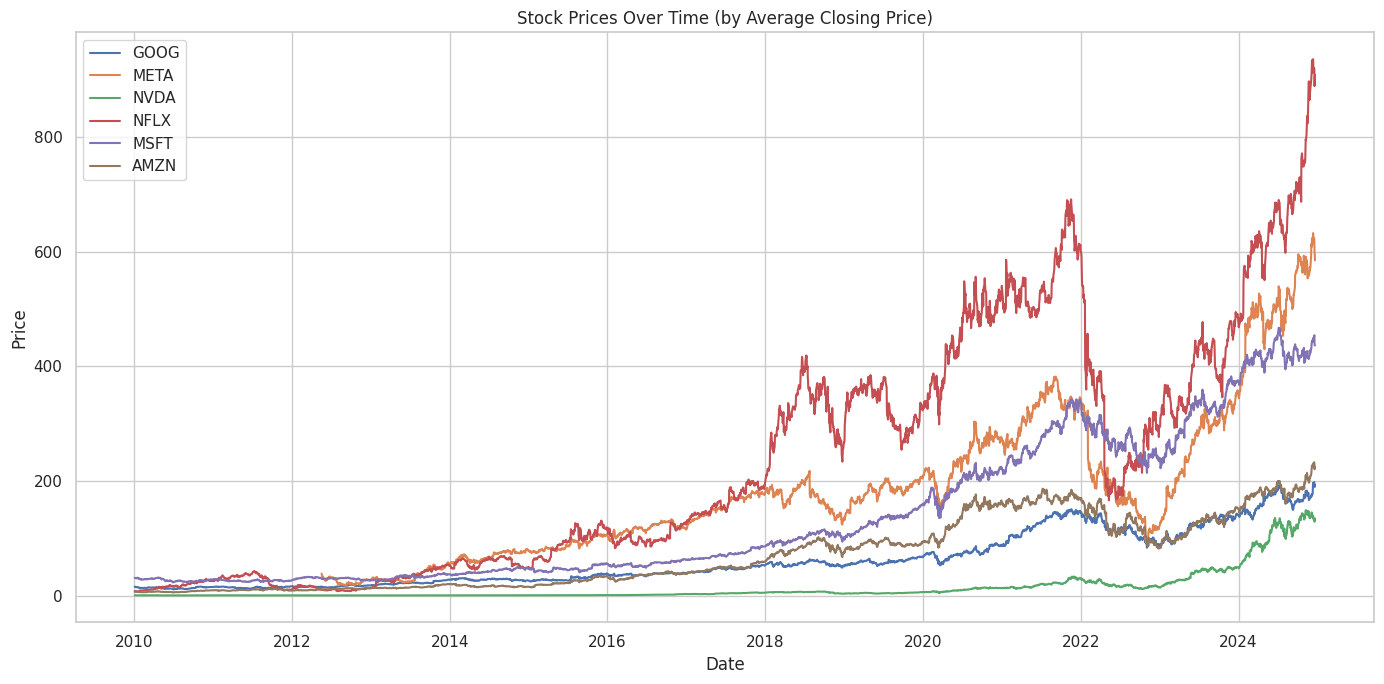

In [ ]:
# Plotting the trading volume over time for specific stocks based on top companies
top_companies = ['GOOG', 'META', 'NVDA', 'NFLX', 'MSFT', 'AMZN']

plt.figure(figsize=(14, 7))
for symbol in top_companies:
    stock_data = stocks_df[stocks_df['Symbol'] == symbol]
    plt.plot(stock_data['Date'], stock_data['Close'], label=symbol)
plt.title('Stock Prices Over Time (by Average Closing Price)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Candlestick Chart based on Stock Selection
symbol = 'NVDA' # example: NVIDIA stock
stock_data = stocks_df[stocks_df['Symbol'] == symbol]
fig = px.line(stock_data, x='Date', y='Close', title=f'Candlestick Chart for {symbol}', labels={'Close': 'Price'})
fig.show()


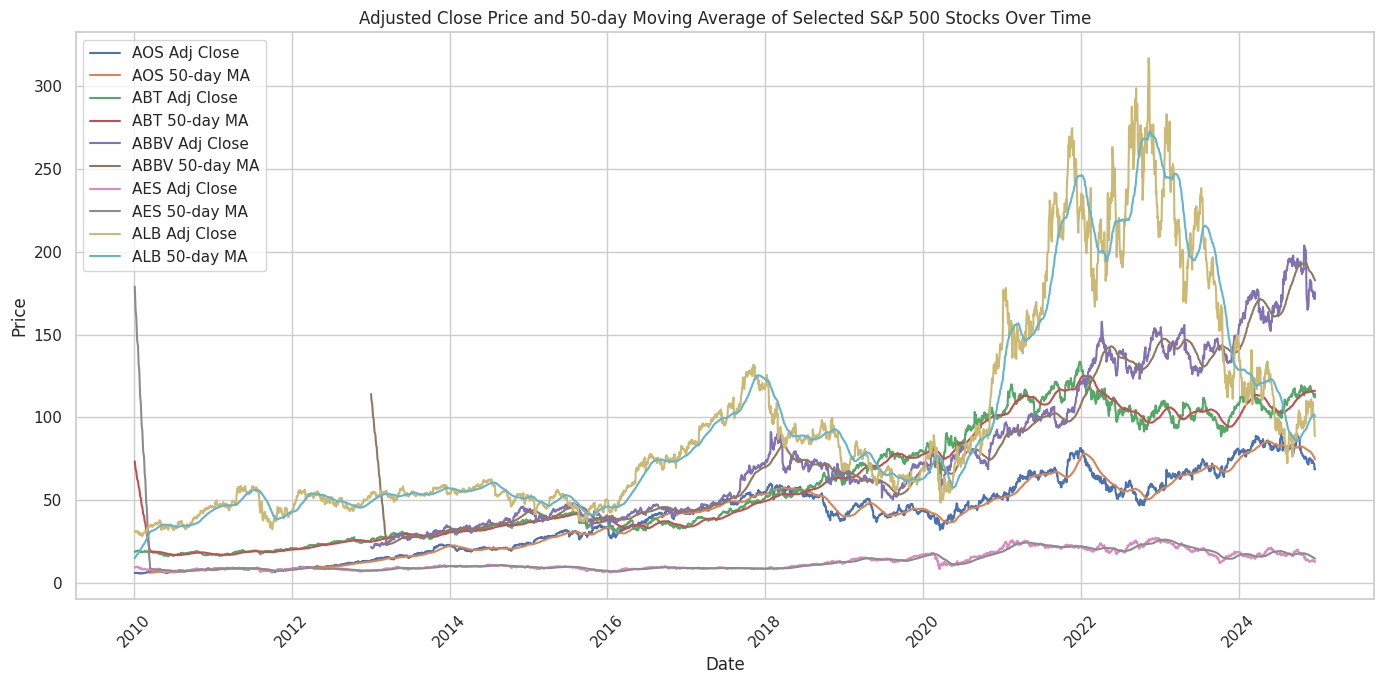

In [ ]:
# Calculate the moving average for the 'Adj Close' column
stocks_df['Moving_Average'] = stocks_df['Adj Close'].rolling(window=50).mean()

# Plotting the adjusted close price and moving average over time for a specific stock (e.g., 'AAPL')
plt.figure(figsize=(14, 7))
for symbol in stocks_df['Symbol'].unique()[:5]:  # Plotting first 5 stocks for clarity
    stock_data = stocks_df[stocks_df['Symbol'] == symbol]
    plt.plot(stock_data['Date'], stock_data['Adj Close'], label=f'{symbol} Adj Close')
    plt.plot(stock_data['Date'], stock_data['Moving_Average'], label=f'{symbol} 50-day MA')
plt.title('Adjusted Close Price and 50-day Moving Average of Selected S&P 500 Stocks Over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

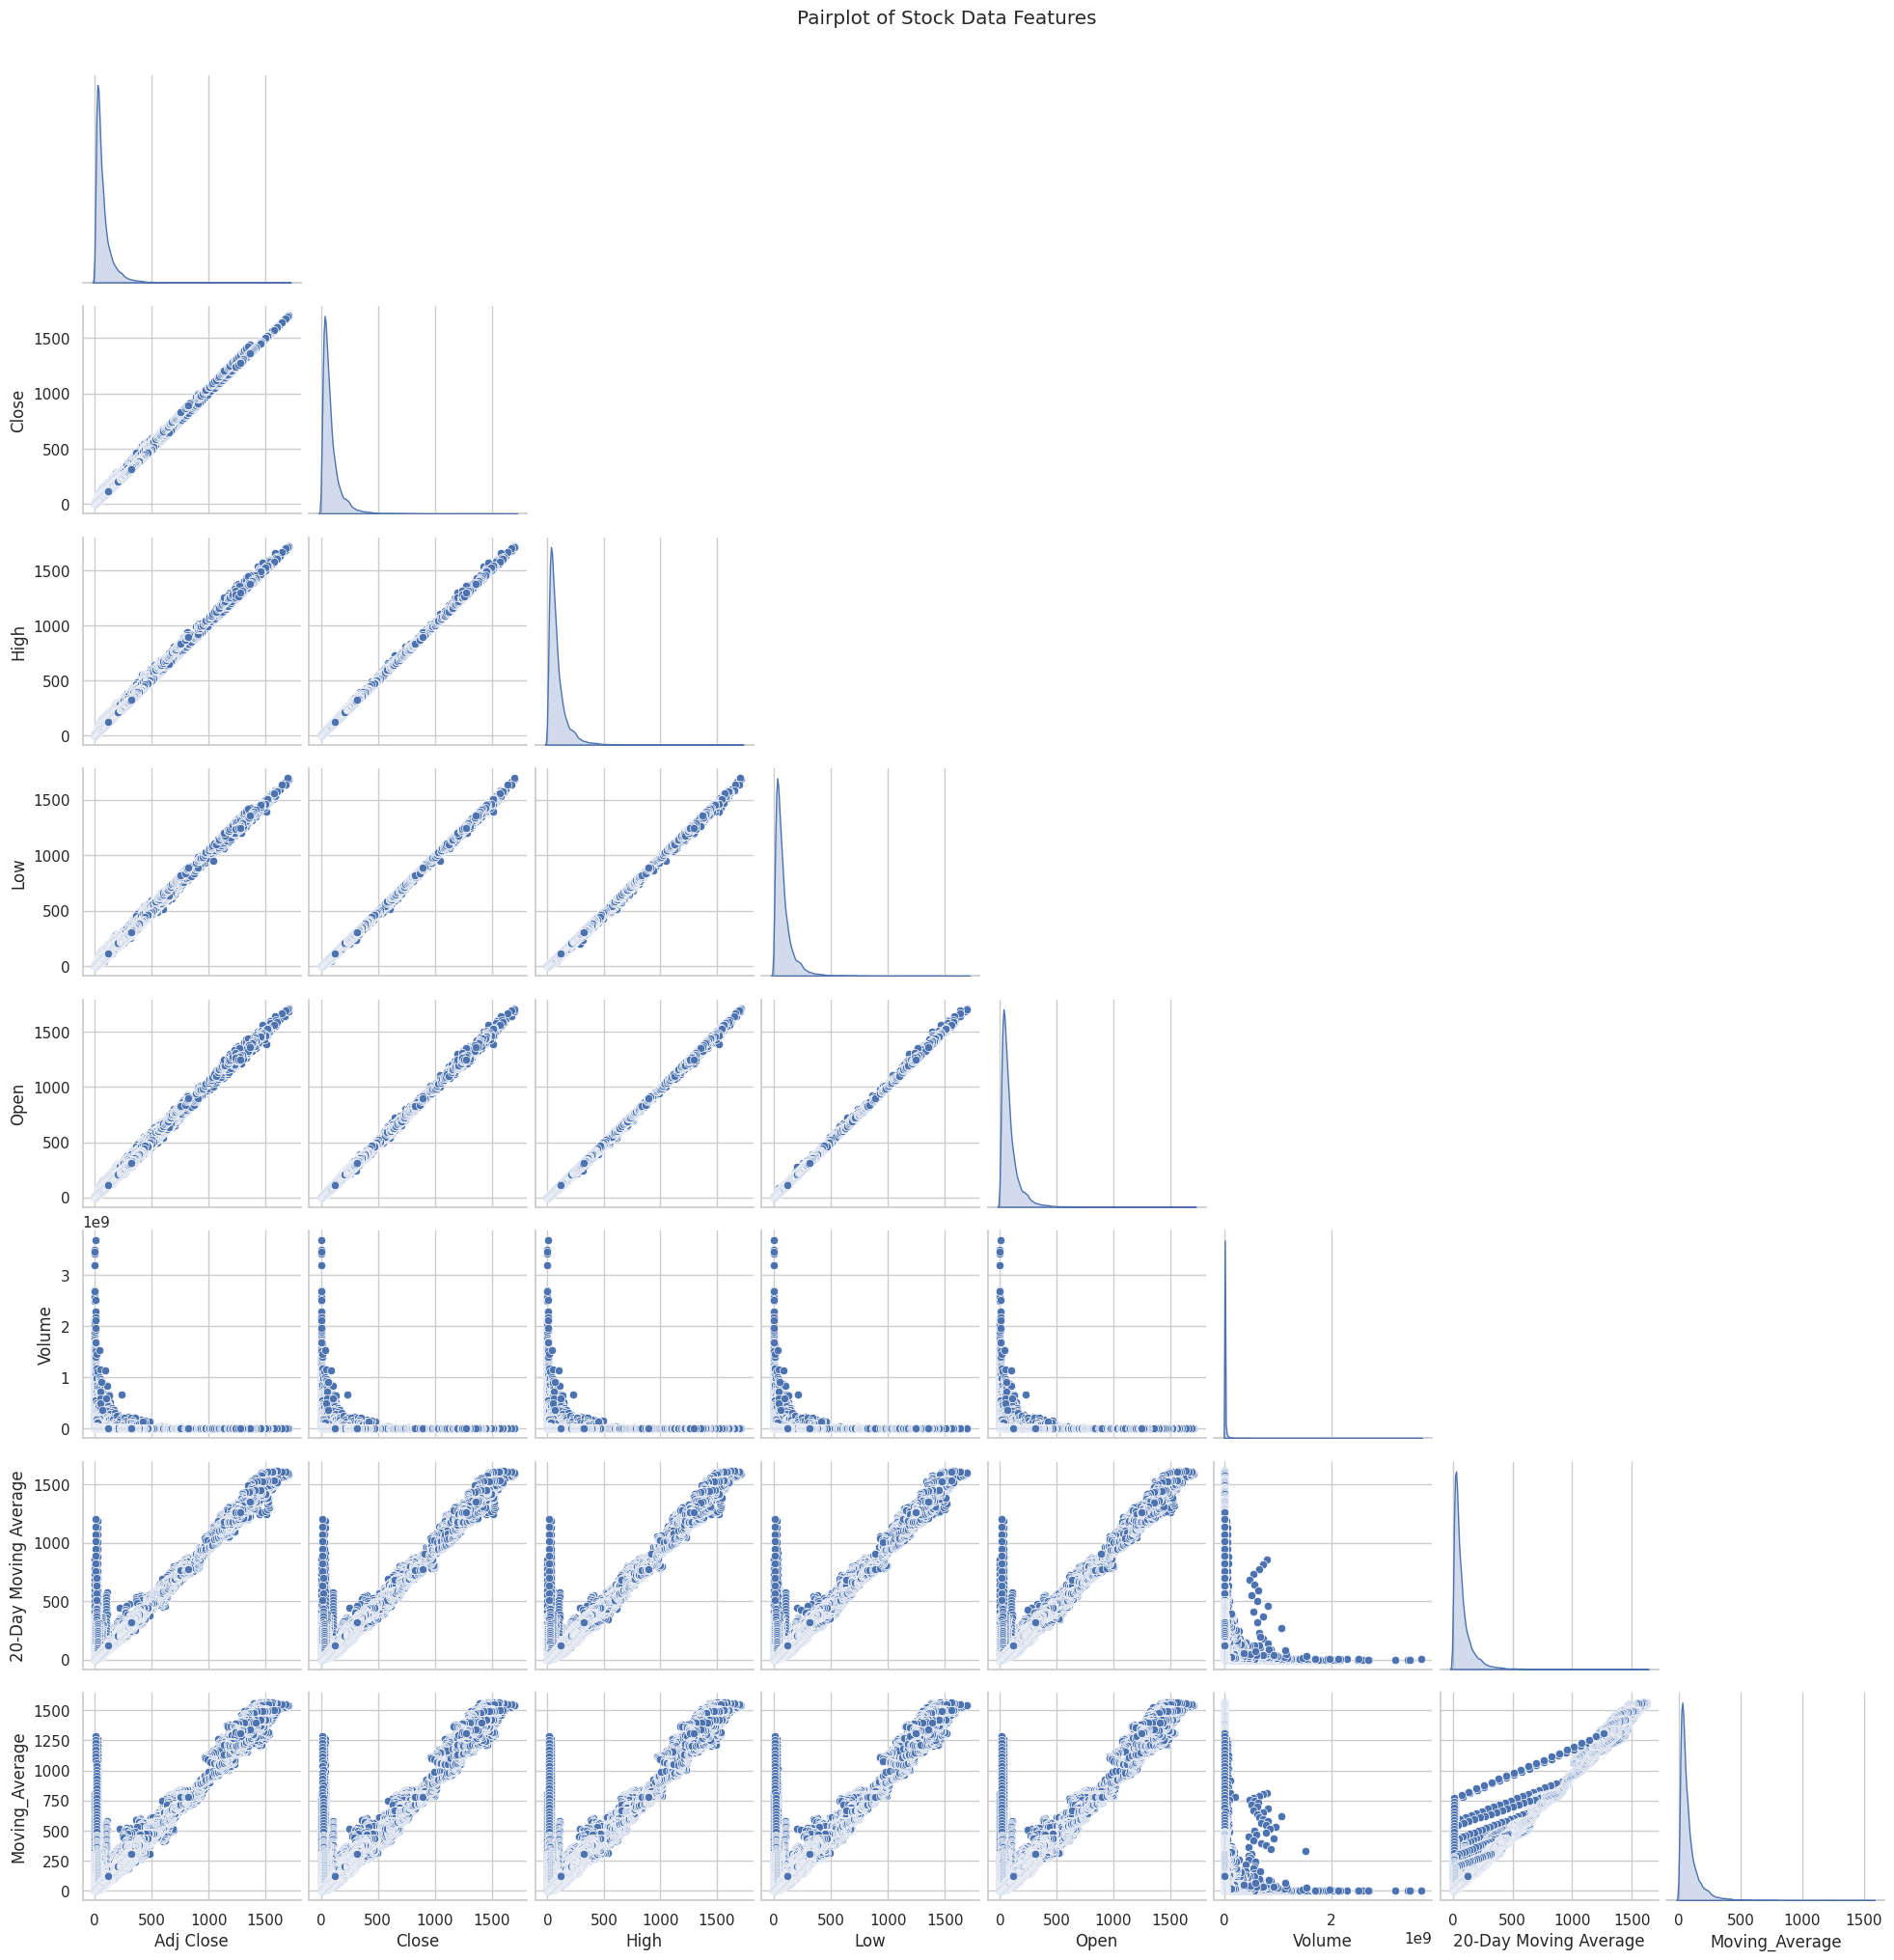

In [ ]:
# Pairplot for Correlation
numeric_features = stocks_df.select_dtypes(include='number')
sns.pairplot(numeric_features, diag_kind='kde', corner=True)
plt.suptitle("Pairplot of Stock Data Features", y=1.02)
plt.show()

Companies:

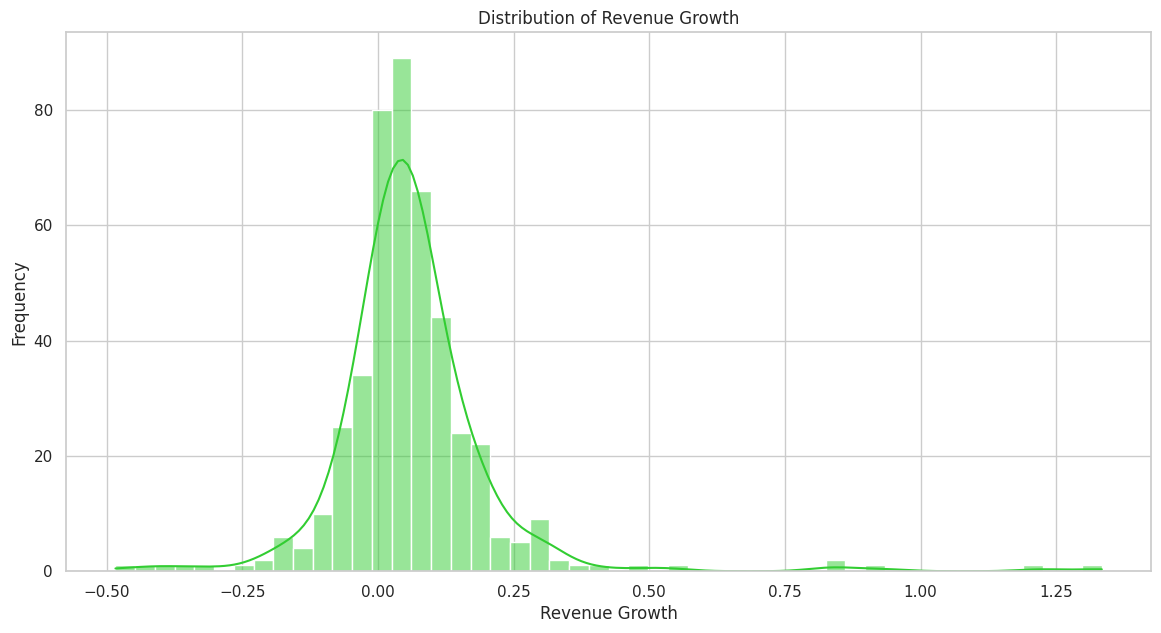

In [ ]:
# Plotting the distribution of Revenue Growth
companies_df['Revenuegrowth'] = companies_df['Revenuegrowth'].replace([np.inf, -np.inf], np.nan)

plt.figure(figsize=(14, 7))
sns.histplot(companies_df['Revenuegrowth'], bins=50, kde=True, color='limegreen')
plt.title('Distribution of Revenue Growth')
plt.xlabel('Revenue Growth')
plt.ylabel('Frequency')
plt.show()

<ipython-input-216-45a4a7b120a9>:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




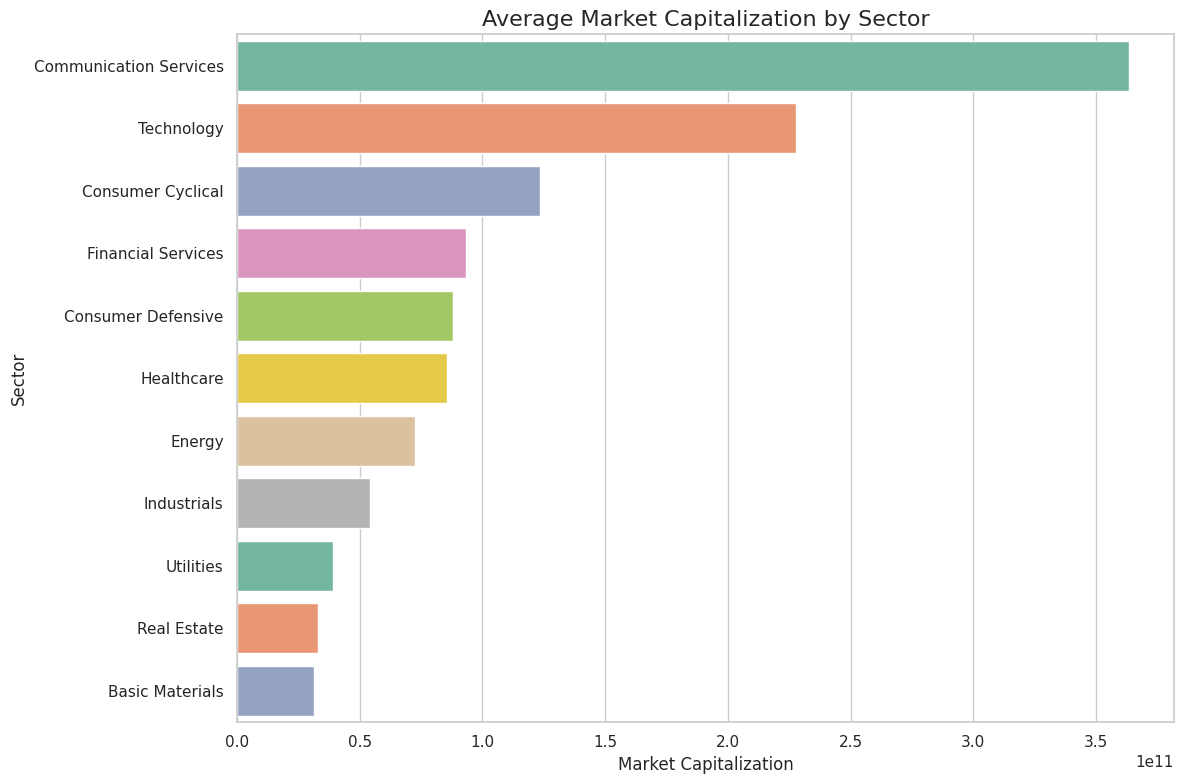

In [ ]:
# Calculate average market capitalization by sector
colors = sns.color_palette("Set2", len(sector_stats))
plt.figure(figsize=(12, 8))
sns.barplot(data=sector_stats.sort_values('Avg_Marketcap', ascending=False), x='Avg_Marketcap', y='Sector', palette=colors)
plt.title('Average Market Capitalization by Sector', fontsize=16)
plt.xlabel('Market Capitalization', fontsize=12)
plt.ylabel('Sector', fontsize=12)
plt.tight_layout()
plt.show()

<Figure size 1400x700 with 0 Axes>

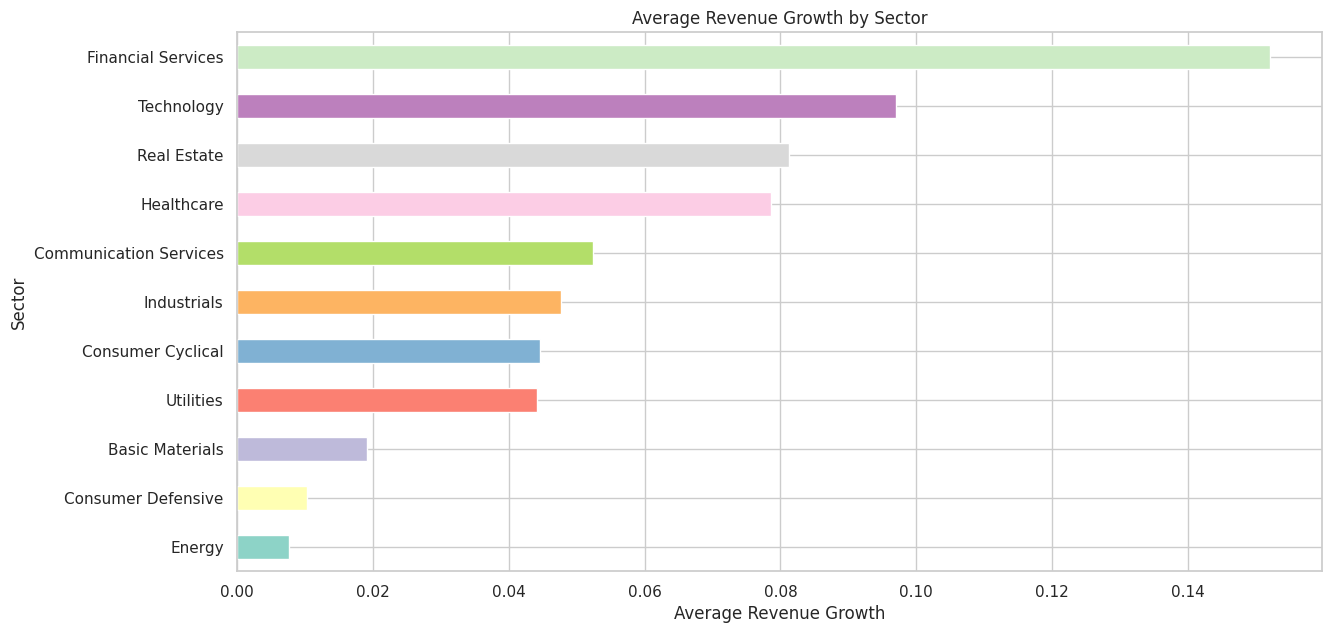

In [ ]:
# Plotting the average revenue growth by sector
plt.figure(figsize=(14, 7))

# Calculate average revenue growth by sector
sector_revenuegrowth = companies_df.groupby('Sector')['Revenuegrowth'].mean().sort_values()

# Choose a color palette
colors = sns.color_palette("Set3", len(sector_revenuegrowth))

# Plotting
plt.figure(figsize=(14, 7))
sector_revenuegrowth.plot(kind='barh', color=colors)
plt.title('Average Revenue Growth by Sector')
plt.xlabel('Average Revenue Growth')
plt.ylabel('Sector')
plt.show()

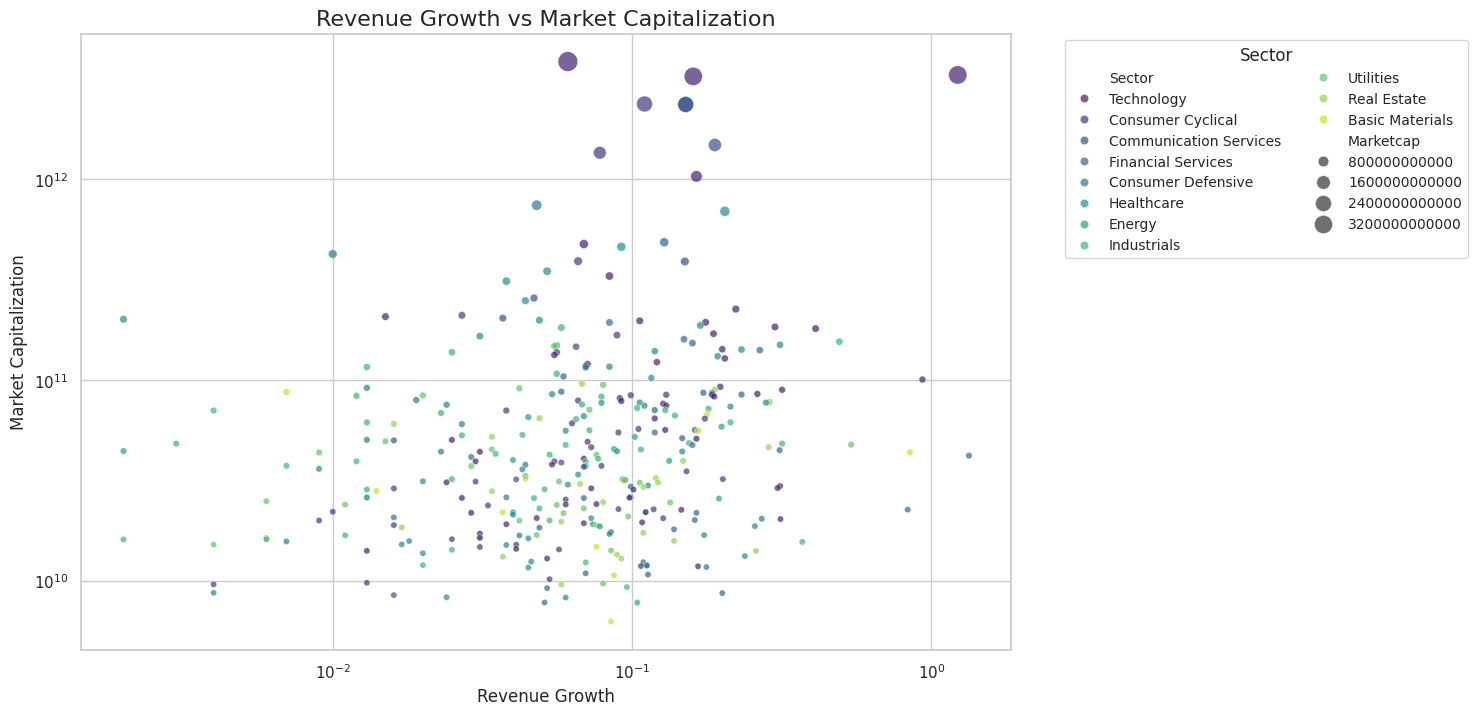

In [ ]:
# Scatter plot of Revenue Growth Vs. Market Capitalization
plt.figure(figsize=(12, 8))
sns.scatterplot(x='Revenuegrowth', y='Marketcap', data=companies_df, hue='Sector',
                palette='viridis', size='Marketcap', sizes=(20, 200), alpha=0.7)
plt.title('Revenue Growth vs Market Capitalization', fontsize=16)
plt.xlabel('Revenue Growth', fontsize=12)
plt.ylabel('Market Capitalization', fontsize=12)
plt.xscale('log')
plt.yscale('log')
plt.legend(title='Sector', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2, fontsize='small')
plt.grid(True)
plt.show()

<ipython-input-219-65abbef060bc>:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




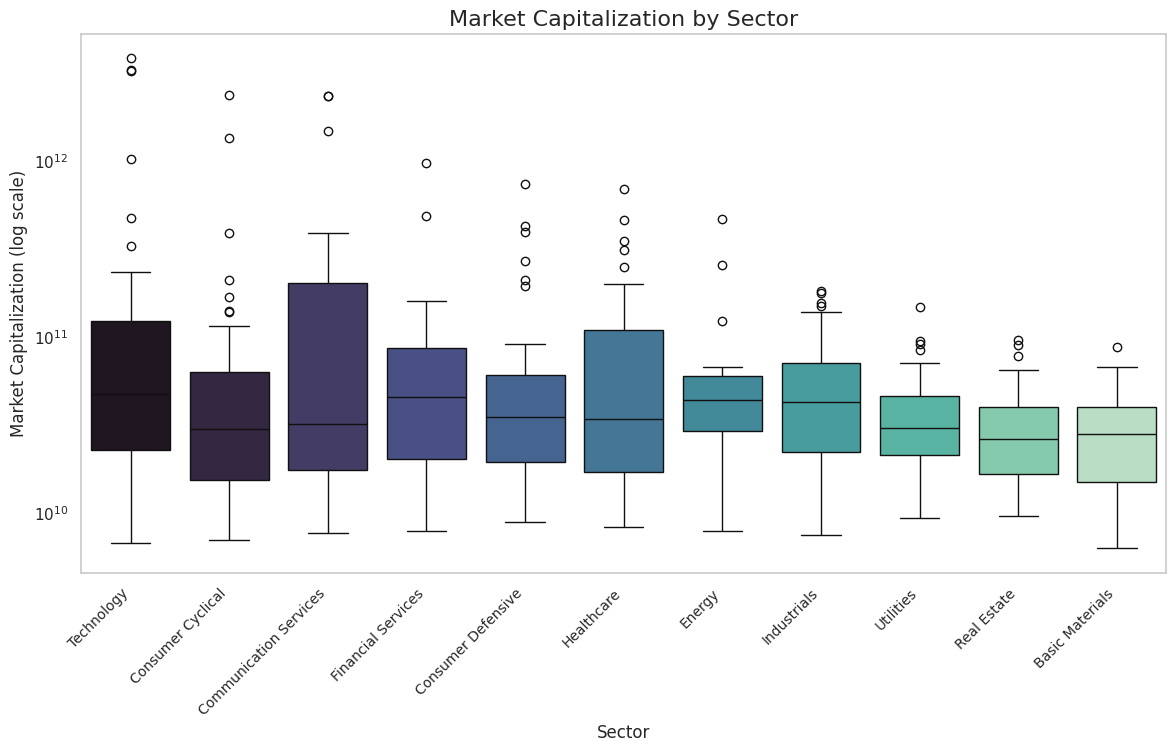

In [ ]:
# Box Plot of Market Capitalization by Sector
plt.figure(figsize=(14, 7))
sns.boxplot(x='Sector', y='Marketcap', data=companies_df, palette='mako')
plt.title('Market Capitalization by Sector', fontsize=16)
plt.xlabel('Sector', fontsize=12)
plt.ylabel('Market Capitalization (log scale)', fontsize=12)
plt.yscale('log')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y')  # Add horizontal gridlines
plt.show()

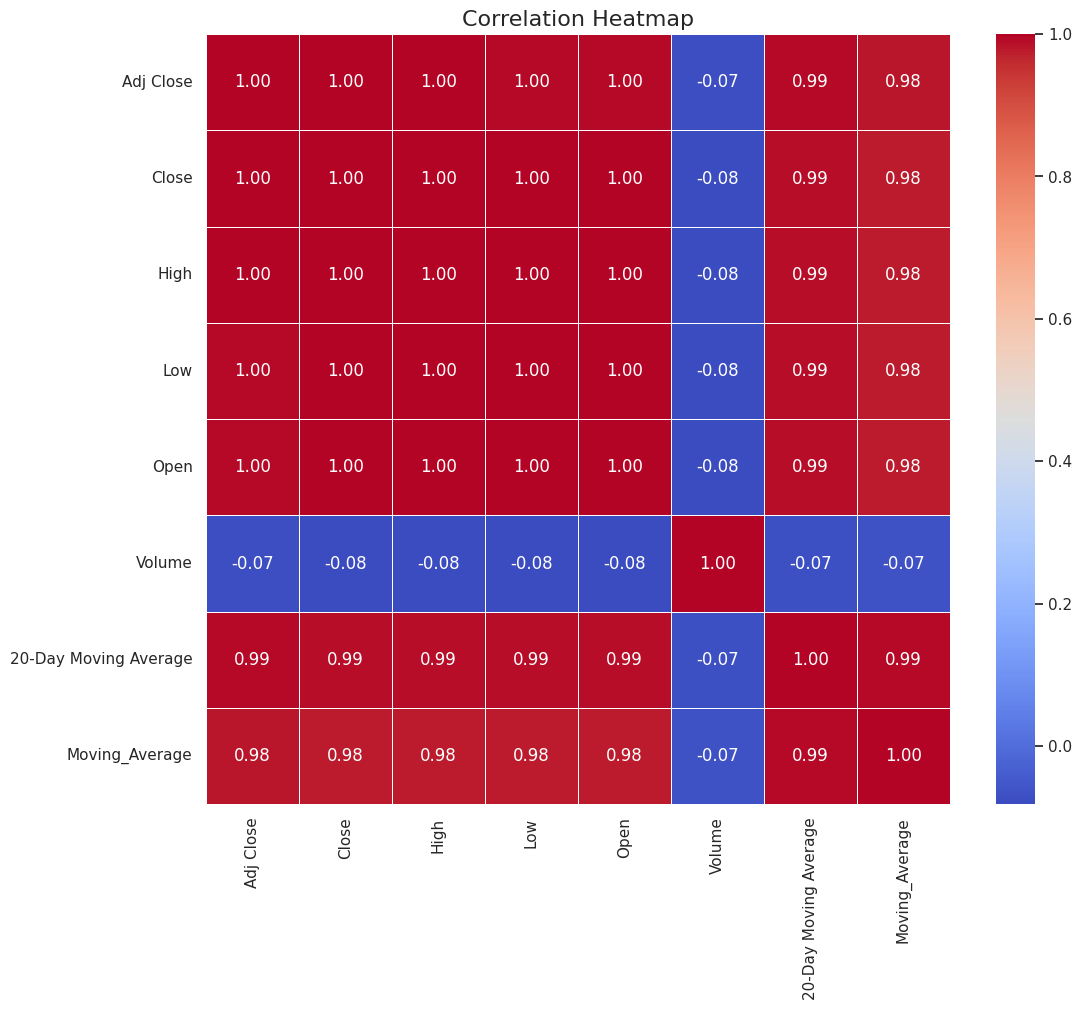

In [ ]:
# Heatmap for Correlation
plt.figure(figsize=(12, 10))
sns.heatmap(numeric_features.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=16)
plt.show()

# **Future Projections for the S&P 500 Index Using Long Short-Term Memory (LSTM) Recurrent Neural Network**

**Building LSTM (RNN) Model**


In [ ]:
# Create sequences for LSTM
def create_sequences(data, seq_length):
    x, y = [], []
    for i in range(seq_length, len(data)):
        x.append(data[i-seq_length:i, 0])
        y.append(data[i, 0])
    return np.array(x), np.array(y)

In [ ]:
# Set sequence length
seq_length = 60
X, y = create_sequences(scaled_index, seq_length)

In [ ]:
# Split the dataset into training and testing sets (80-20 split)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"Training size: {len(X_train)}, Testing size: {len(X_test)}")

Training size: 1965, Testing size: 492


In [ ]:
# Reshape input data for LSTM [samples, time steps, features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

In [ ]:
# Define the model-building function for Keras Tuner
def build_lstm_model(hp):
    model = Sequential()
    model.add(LSTM(hp.Int('lstm_1_units', min_value=32, max_value=256, step=32),
                   return_sequences=True, input_shape=(seq_length, 1)))
    model.add(Dropout(hp.Float('dropout_1', min_value=0.0, max_value=0.5, step=0.1)))

    model.add(LSTM(hp.Int('lstm_2_units', min_value=32, max_value=256, step=32),
                   return_sequences=True))
    model.add(Dropout(hp.Float('dropout_2', min_value=0.0, max_value=0.5, step=0.1)))

    model.add(LSTM(hp.Int('lstm_3_units', min_value=32, max_value=256, step=32),
                   return_sequences=False))
    model.add(Dropout(hp.Float('dropout_3', min_value=0.0, max_value=0.5, step=0.1)))

    model.add(Dense(hp.Int('dense_units', min_value=16, max_value=64, step=16)))
    model.add(Dense(1))

    model.compile(optimizer='adam',
                      loss='mean_squared_error',
                      metrics=[metrics.mae, metrics.mse])

    return model

In [ ]:
# Initialize the Keras Tuner
tuner = RandomSearch(
    build_lstm_model,
    objective='val_loss',
    max_trials=20,  # Number of different hyperparameter combinations to try
    executions_per_trial=2,  # Number of models to train per trial
    directory='lstm_tuner',
    project_name='sp500_lstm'
)

Reloading Tuner from lstm_tuner/sp500_lstm/tuner0.json


In [ ]:
# Add early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5)

In [ ]:
# Perform the hyperparameter search
tuner.search(X_train, y_train, epochs=20, validation_split=0.2, callbacks=[early_stopping], verbose=1)

Trial 13 Complete [00h 14m 02s]
val_loss: 0.0004961288359481841

Best val_loss So Far: 0.00046831302461214364
Total elapsed time: 03h 13m 55s

Search: Running Trial #14

Value             |Best Value So Far |Hyperparameter
32                |256               |lstm_1_units
0.2               |0                 |dropout_1
64                |256               |lstm_2_units
0.2               |0                 |dropout_2
224               |256               |lstm_3_units
0.1               |0.2               |dropout_3
16                |16                |dense_units

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 281ms/step - accuracy: 0.0000e+00 - loss: 0.0082 - mean_absolute_error: 0.0589 - mean_squared_error: 0.0082 - val_accuracy: 0.0000e+00 - val_loss: 0.0013 - val_mean_absolute_error: 0.0306 - val_mean_squared_error: 0.0013
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 269ms/step - accuracy: 0.0000e+00 - loss: 7.7943e-04 - mean_absolute_error: 0.0193 - mean_squared_error: 7.7943e-04 - val_ac

In [ ]:
# Get the best model
best_hps = tuner.get_best_models(num_models=1)[0]
print(f"Best hyperparameters: {best_hps.summary()}")

In [ ]:
# Train the best model
history = best_hps.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1)

In [ ]:
# Make predictions
predictions = best_hps.predict(X_test)
predictions = scaler.inverse_transform(predictions)  # Inverse transform to get actual values
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

In [ ]:
# Create a date range for the test set
test_dates = index_df.index[-len(y_test):]  # Get the last 'len(y_test)' dates from the index_df

# Plot predictions vs actual values with actual dates
plt.figure(figsize=(12, 6))
plt.plot(test_dates, y_test_actual, label='Actual S&P 500', color='blue')
plt.plot(test_dates, predictions, label='Predicted S&P 500', color='red')
plt.title('S&P 500 Index Prediction (LSTM with Keras Tuner)')
plt.xlabel('Date')
plt.ylabel('Index Value')
plt.legend()
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()


In [ ]:
# Calculate and print evaluation metrics
mse = np.mean((y_test_actual - predictions) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test_actual - predictions))

print(f'\nModel Performance Metrics:')
print(f'Mean Squared Error: {mse:.2f}')
print(f'Root Mean Squared Error: {rmse:.2f}')
print(f'Mean Absolute Error: {mae:.2f}')